In [ ]:
!pip install -q pandas matplotlib openpyxl numpy


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, LogLocator, NullFormatter

plt.rcParams.update({
    "font.family":      "serif",
    "font.serif":       ["DejaVu Serif", "Times New Roman", "Times"],
    "font.size":        12,
    "axes.linewidth":   1.1,
    "mathtext.fontset": "dejavuserif",
    "savefig.dpi":      300,
})

# ---- single energy window constant -----------------------------------------
E_MIN, E_MAX = 1.0, 20.0     # MeV

# ---- unit conversions -------------------------------------------------------
B_TO_MB   = 1000.0           # barns -> millibarns
EV_TO_MEV = 1e-6             # eV    -> MeV

# ---- reaction / output naming ----------------------------------------------
REACTION = "Fe-56(n,n')Fe-56*"
SLUG     = "Fe56_ninl"
# ENDF file is internally JENDL-5 (see header) -> label the curve accordingly.
ENDF_LABEL = "ENDF/B-VIII.1"

# ---- y-limit: overall peak ~2387 mb (JENDL-5) -> top=6000 gives log headroom -
Y_TOP = 6000

# ---- ROBUST keyword file finder --------------------------------------------
def _norm(s):
    return s.lower().replace(" ", "").replace("_", "").replace("-", "")

def resolve(key):
    sigs = {"EXFOR": "exfor", "TENDL": "tendl", "ENDF": "endf",
            "JEFF": "jeff", "TALYS": "talys"}
    want = sigs[key]
    for fn in os.listdir("."):
        if fn.startswith("."):
            continue
        n = _norm(fn)
        if want in n or (key == "ENDF" and ("jendl" in n or "ebdf" in n)):
            return fn
    return None

In [ ]:
def _window(df):
    df = df.dropna(subset=["energy_MeV", "xs_mb"])
    df = df[(df["energy_MeV"] >= E_MIN) & (df["energy_MeV"] <= E_MAX)]
    return df[df["xs_mb"] > 0].sort_values("energy_MeV").reset_index(drop=True)

def parse_exfor(path):
    """EXFOR csv: energy_MeV, d_energy_MeV, cross_section_b, d_cross_section_b,
    author, year (MeV / barns)."""
    df = pd.read_csv(path)
    out = pd.DataFrame({
        "energy_MeV": pd.to_numeric(df["energy_MeV"], errors="coerce"),
        "xs_mb":      pd.to_numeric(df["cross_section_b"], errors="coerce") * B_TO_MB,
        "dE_MeV":     pd.to_numeric(df.get("d_energy_MeV", 0), errors="coerce").fillna(0),
        "dxs_mb":     pd.to_numeric(df.get("d_cross_section_b", 0), errors="coerce").fillna(0) * B_TO_MB,
        "author":     df.get("author", "Unknown").astype(str).str.strip(),
        "year":       pd.to_numeric(df.get("year", 0), errors="coerce").fillna(0).astype(int),
    })
    out = _window(out)
    out["label"] = out["author"] + " (" + out["year"].astype(str) + ")"
    return out

def parse_talys(path):
    """TALYS xlsx. Two supported layouts:
      (a) paired (Energy[MeV], sigma[mb]) blocks for ldmodel1-4 -> use ldmodel1;
      (b) a simple 2-column sheet (Energy [MeV], sigma [mb]).
    '-' placeholders are coerced to NaN and dropped. Already MeV / mb."""
    raw = pd.read_excel(path, header=None)
    titles = [str(t) for t in raw.iloc[0].tolist()]
    start_col = 0
    for i, t in enumerate(titles):
        if "ldmodel1" in t.replace(" ", "").lower():
            start_col = i
            break
    e  = pd.to_numeric(raw.iloc[2:, start_col],     errors="coerce")
    xs = pd.to_numeric(raw.iloc[2:, start_col + 1], errors="coerce")
    # fall back to the plain 2-column layout (header in row 0, data from row 1)
    if e.notna().sum() == 0:
        e  = pd.to_numeric(raw.iloc[1:, 0], errors="coerce")
        xs = pd.to_numeric(raw.iloc[1:, 1], errors="coerce")
    return _window(pd.DataFrame({"energy_MeV": e.values, "xs_mb": xs.values}))

def parse_tendl(path):
    """TENDL export, csv OR xlsx. csv: skip '#'/'##' headers and the 'E,xs' line.
    xlsx (YANDF): a '# header:' blob sits in row 0; real header is row 1, data
    from row 2. Already MeV / mb."""
    if path.lower().endswith((".xlsx", ".xls")):
        raw = pd.read_excel(path, header=None)
        e  = pd.to_numeric(raw.iloc[2:, 0], errors="coerce")
        xs = pd.to_numeric(raw.iloc[2:, 1], errors="coerce")
        return _window(pd.DataFrame({"energy_MeV": e.values, "xs_mb": xs.values}))
    rows = []
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            s = line.strip().strip(",").strip()
            if not s or s.startswith("#") or s.startswith('"'):
                continue
            if "e,xs" in s.lower() or s.lower().startswith("e,"):
                continue
            parts = [p for p in s.replace(";", ",").split(",") if p != ""]
            if len(parts) < 2:
                continue
            try:
                rows.append((float(parts[0]), float(parts[1])))
            except ValueError:
                continue
    return _window(pd.DataFrame(rows, columns=["energy_MeV", "xs_mb"]))

def _endf_float(tok):
    """Decode ENDF-6 float notation: '1.947136+6' -> 1.947136e6, '-2.5-3' etc."""
    tok = tok.strip()
    if not tok:
        return None
    if "e" in tok.lower():
        return float(tok)
    # insert 'e' before a +/- exponent sign that follows a digit or '.'
    for i in range(1, len(tok)):
        if tok[i] in "+-" and tok[i - 1] not in "eE":
            try:
                return float(tok[:i] + "e" + tok[i:])
            except ValueError:
                return None
    return float(tok)

def parse_endf(path):
    """Dual-mode ENDF/JENDL parser.
    Mode A — raw ENDF-6: lines carry an MF/MT tag (e.g. '3103') in cols 67-75 and
             use ENDF float notation (1.947136+6). Detected first.
    Mode B — simple point list: '#'-comment header then 'E[eV]  Sig[b]  Interp'.
    Both -> eV->MeV, b->mb."""
    raw_endf6 = False
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            tag = line[66:75].strip() if len(line) >= 75 else ""
            if tag == "3103" or (len(tag) == 4 and tag.startswith("3") and tag.isdigit()):
                raw_endf6 = True
                break

    rows = []
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            if raw_endf6:
                tag = line[66:75].strip() if len(line) >= 75 else ""
                if not (tag.startswith("3") and tag.isdigit()):
                    continue
                c0, c1 = line[0:11], line[11:22]
                e, xs = _endf_float(c0), _endf_float(c1)
                if e is None or xs is None:
                    continue
                rows.append((e * EV_TO_MEV, xs * B_TO_MB))
            else:
                s = line.strip()
                if not s or s.startswith("#"):
                    continue
                parts = s.split()
                if len(parts) < 2:
                    continue
                try:
                    rows.append((float(parts[0]) * EV_TO_MEV, float(parts[1]) * B_TO_MB))
                except ValueError:
                    continue
    return _window(pd.DataFrame(rows, columns=["energy_MeV", "xs_mb"]))

def parse_jeff(path):
    """JEFF-4.0 csv: energy_MeV, cross_section_b (MeV / barns). Tolerates an
    Energy_eV / CrossSection_barns layout too."""
    df = pd.read_csv(path)
    if "energy_MeV" in df.columns:
        e = pd.to_numeric(df["energy_MeV"], errors="coerce")
    elif "Energy_MeV" in df.columns:
        e = pd.to_numeric(df["Energy_MeV"], errors="coerce")
    else:
        e = pd.to_numeric(df["Energy_eV"], errors="coerce") * EV_TO_MEV
    if "cross_section_b" in df.columns:
        xs = pd.to_numeric(df["cross_section_b"], errors="coerce") * B_TO_MB
    else:
        xs = pd.to_numeric(df["CrossSection_barns"], errors="coerce") * B_TO_MB
    return _window(pd.DataFrame({"energy_MeV": e, "xs_mb": xs}))

PARSERS = {"EXFOR": parse_exfor, "TENDL": parse_tendl, "ENDF": parse_endf,
           "JEFF": parse_jeff, "TALYS": parse_talys}

data = {}
for key, parser in PARSERS.items():
    path = resolve(key)
    if path is None:
        print(f"[WARNING] {key}: no matching file uploaded — skipping.")
        data[key] = None
        continue
    try:
        data[key] = parser(path)
        print(f"[OK] {key:5s}: {len(data[key]):5d} points  from '{path}'")
    except Exception as e:
        print(f"[ERROR] {key}: failed to parse '{path}': {e}")
        data[key] = None


[OK] EXFOR: 13402 points  from 'Fe-56(n,inl)Fe-56star exfor.csv'
[OK] TENDL:   361 points  from 'Fe56(n,n_)Fe56 cross section tendl.xlsx'
[OK] ENDF :  7435 points  from 'Fe 56 (n,n_)  endf.txt'
[OK] JEFF :  2279 points  from 'Fe-56(n,inl)Fe-56star_JEFF40.csv'
[OK] TALYS:   130 points  from 'Fe-56  ( n, n_ ) Fe-56 talys.xlsx'


Saved plot -> Fe56_ninl_combined_comparison_plot.png


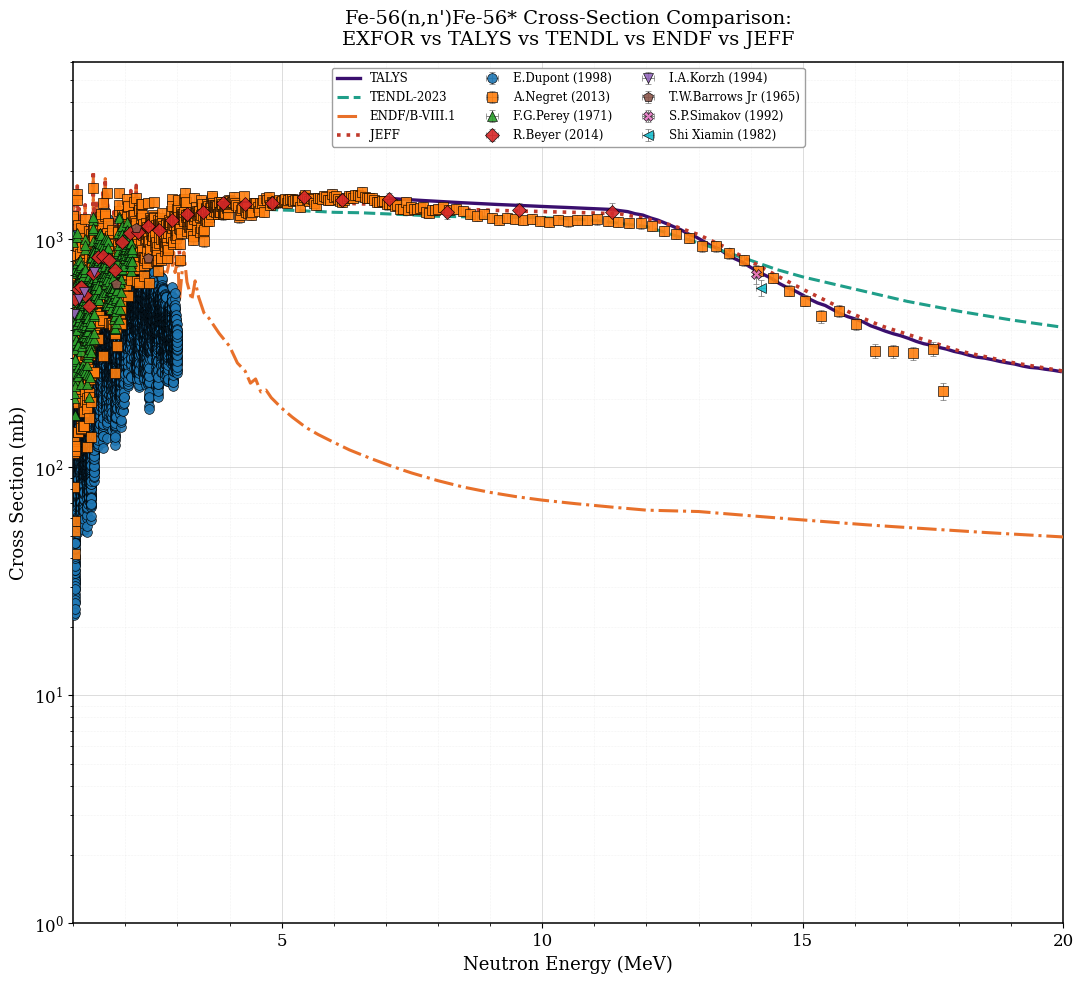

In [ ]:
fig, ax = plt.subplots(figsize=(11, 10))

CURVE_STYLE = {
    "TALYS": dict(color="#3a0f6e", ls="-",  lw=2.4, label="TALYS"),
    "TENDL": dict(color="#1f9e89", ls="--", lw=2.2, label="TENDL-2023"),
    "ENDF":  dict(color="#e8702a", ls="-.", lw=2.2, label=ENDF_LABEL),
    "JEFF":  dict(color="#c0392b", ls=":",  lw=2.6, label="JEFF"),
}
for key in ["TALYS", "TENDL", "ENDF", "JEFF"]:
    df = data.get(key)
    if df is not None and len(df):
        ax.plot(df["energy_MeV"], df["xs_mb"], **CURVE_STYLE[key], zorder=3)

exfor = data.get("EXFOR")
if exfor is not None and len(exfor):
    # show ALL authors individually (no "Other measurements" group)
    counts = exfor["label"].value_counts()
    TOP_N = len(counts)
    top_labels = list(counts.index[:TOP_N])
    exfor = exfor[exfor["label"].isin(top_labels)].copy()
    # Hand-picked high-contrast palette + distinct shapes: every author is
    # separable by BOTH colour and marker shape (no muddy tab20 near-duplicates).
    palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd",
               "#8c564b", "#e377c2", "#17becf", "#bcbd22", "#393b79",
               "#e6550d", "#31a354"]
    markers = ["o", "s", "^", "D", "v", "p", "X", "<", "*", ">", "h", "P"]
    for i, lab in enumerate(top_labels):
        sub = exfor[exfor["label"] == lab]
        ax.errorbar(
            sub["energy_MeV"], sub["xs_mb"],
            yerr=sub["dxs_mb"].where(sub["dxs_mb"] > 0, np.nan),
            xerr=sub["dE_MeV"].where(sub["dE_MeV"] > 0, np.nan),
            fmt=markers[i % len(markers)],
            color=palette[i % len(palette)], ecolor="0.4",
            markersize=7, alpha=0.9, markeredgecolor="black", markeredgewidth=0.5,
            elinewidth=0.6, capsize=2, capthick=0.6,
            linestyle="none", label=lab, zorder=4,
        )

ax.set_xscale("linear")
ax.set_yscale("log")
ax.set_xlim(E_MIN, E_MAX)
ax.set_ylim(1, Y_TOP)
ax.set_xlabel("Neutron Energy (MeV)", fontsize=13)
ax.set_ylabel("Cross Section (mb)", fontsize=13)
ax.set_title(
    f"{REACTION} Cross-Section Comparison:\n"
    "EXFOR vs TALYS vs TENDL vs ENDF vs JEFF",
    fontsize=14, pad=12,
)

# x: linear ticks at 5/10/15/20 major, 1 MeV minor
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.xaxis.set_minor_locator(MultipleLocator(1))
# y: decade majors, sub-decade minors unlabeled
ax.yaxis.set_major_locator(LogLocator(base=10))
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.grid(which="major", ls="-", lw=0.6, alpha=0.5)
ax.grid(which="minor", ls=":", lw=0.4, alpha=0.3)

ax.legend(loc="upper center", ncol=3, fontsize=8.5,
          framealpha=0.95, edgecolor="0.6")

fig.tight_layout()
OUT_PNG = f"{SLUG}_combined_comparison_plot.png"
fig.savefig(OUT_PNG, dpi=300, bbox_inches="tight")
print(f"Saved plot -> {OUT_PNG}")



In [ ]:
frames = []
for key, df in data.items():
    if df is None or not len(df):
        continue
    tmp = df.copy()
    tmp["source"] = key
    if key == "EXFOR":
        tmp = tmp[["source", "energy_MeV", "xs_mb", "dE_MeV", "dxs_mb", "author", "year"]]
    else:
        tmp = tmp[["source", "energy_MeV", "xs_mb"]]
        tmp["dE_MeV"] = np.nan; tmp["dxs_mb"] = np.nan
        tmp["author"] = np.nan; tmp["year"] = np.nan
    frames.append(tmp)

if not frames:
    raise RuntimeError(
        "No data loaded — every source was skipped. Check the [WARNING] lines "
        "from Cell 3 and confirm all 5 files are uploaded (Files panel)."
    )

combined = pd.concat(frames, ignore_index=True)
combined = combined.sort_values(["source", "energy_MeV"]).reset_index(drop=True)
OUT_CSV = f"{SLUG}_parsed_data.csv"
combined.to_csv(OUT_CSV, index=False)
print(f"Saved data -> {OUT_CSV}  ({len(combined)} rows)")

OUT_TXT = f"{SLUG}_summary_statistics.txt"
with open(OUT_TXT, "w") as f:
    f.write(f"{REACTION} Cross-Section Data — Summary Statistics\n")
    f.write("=" * 60 + "\n")
    f.write(f"Comparison energy window: {E_MIN}-{E_MAX} MeV\n\n")
    for key, df in data.items():
        f.write(f"[{key}]\n")
        if df is None or not len(df):
            f.write("  (no data / file missing)\n\n"); continue
        f.write(f"  points        : {len(df)}\n")
        f.write(f"  energy range  : {df['energy_MeV'].min():.4g} - {df['energy_MeV'].max():.4g} MeV\n")
        f.write(f"  xs min        : {df['xs_mb'].min():.4g} mb\n")
        f.write(f"  xs max        : {df['xs_mb'].max():.4g} mb\n")
        if key == "EXFOR":
            f.write(f"  unique authors: {df['author'].nunique()}\n")
            f.write(f"  year range    : {int(df['year'].min())}-{int(df['year'].max())}\n")
        f.write("\n")
print(f"Saved stats -> {OUT_TXT}")
print(open(OUT_TXT).read())

Saved data -> Fe56_ninl_parsed_data.csv  (32346 rows)
Saved stats -> Fe56_ninl_summary_statistics.txt
Fe-56(n,n')Fe-56* Cross-Section Data — Summary Statistics
Comparison energy window: 1.0-20.0 MeV

[EXFOR]
  points        : 13402
  energy range  : 1 - 17.7 MeV
  xs min        : 22.48 mb
  xs max        : 1684 mb
  unique authors: 8
  year range    : 1965-2014

[TENDL]
  points        : 361
  energy range  : 1 - 20 MeV
  xs min        : 410.6 mb
  xs max        : 1389 mb

[ENDF]
  points        : 16174
  energy range  : 1 - 20 MeV
  xs min        : 45.88 mb
  xs max        : 2387 mb

[JEFF]
  points        : 2279
  energy range  : 1 - 20 MeV
  xs min        : 51.91 mb
  xs max        : 1999 mb

[TALYS]
  points        : 130
  energy range  : 1.15 - 19.94 MeV
  xs min        : 263 mb
  xs max        : 1549 mb




In [ ]:
plt.show()